# Semantic Segmentation: One Label per Pixel

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roboflow/supervision/blob/develop/docs/notebooks/semantic-segmentation.ipynb)

A semantic segmentation model labels every pixel of an image with a class: *road*, *building*, *sky*. It does not separate two people standing side by side, because both pixels are just `person`. Models return this as one dense label map of shape `(H, W)` holding a class id per pixel.

`sv.Detections.from_semantic_segmentation` turns that label map into the `sv.Detections` that every annotator, filter and sink in supervision already understands. It makes one detection per class id found in the map, with a mask, a tight box and a `class_name`.

This cookbook runs three semantic segmentation models from the Hugging Face hub through the same two lines of supervision code:

- **SegFormer**: a lightweight transformer encoder with a plain MLP decoder.
- **Mask2Former**: a mask-classification model that predicts a set of masks and classes.
- **OneFormer**: a single model that can do semantic, instance and panoptic segmentation, steered by a task prompt.

All three are trained on ADE20K, a scene-parsing dataset with 150 classes, so their outputs are directly comparable.

## Install required packages

- `supervision`: `from_semantic_segmentation` ships in `0.32.0`. Until it is released, install from the `develop` branch.
- `transformers` and `torch`: run the three models.

In [ ]:
%pip install -q "supervision @ git+https://github.com/roboflow/supervision.git@develop" transformers torch

In [1]:
%matplotlib inline

import urllib.request

import numpy as np
import torch
from PIL import Image
from transformers import (
    AutoImageProcessor,
    AutoModelForUniversalSegmentation,
    OneFormerForUniversalSegmentation,
    OneFormerProcessor,
    SegformerForSemanticSegmentation,
)

import supervision as sv

print(sv.__version__)

0.32.0.dev0


## Download the sample image

A stone house with a tiled roof, a wall, trees, grass and sky: enough different classes to tell the models apart. The photo is a validation image from the ADE20K scene-parsing dataset, which is released for non-commercial research use.

Image size: 683x512


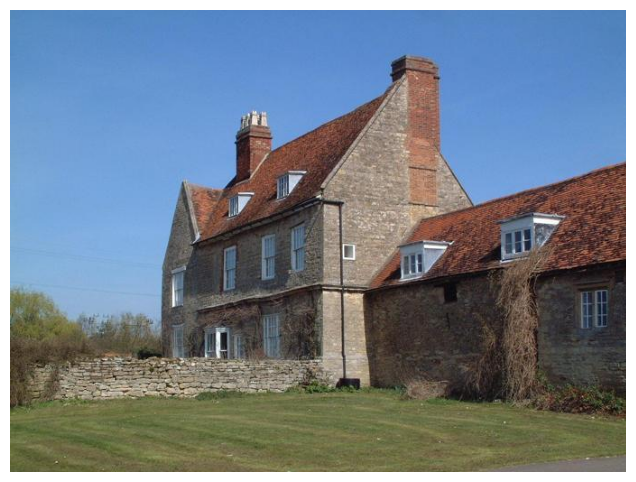

In [2]:
image_url = "https://huggingface.co/datasets/hf-internal-testing/fixtures_ade20k/resolve/main/ADE_val_00000001.jpg"
image_path = "ade20k-house.jpg"
urllib.request.urlretrieve(image_url, image_path)
pil_image = Image.open(image_path).convert("RGB")
image = sv.pillow_to_cv2(pil_image)
height, width = image.shape[:2]
print(f"Image size: {width}x{height}")

sv.plot_image(image, size=(10, 6))

## From a label map to `sv.Detections`

Every model below ends the same way: a post-processing step yields an integer array of shape `(H, W)` at the image's size, and a `{id: name}` table describes the ids. `from_semantic_segmentation` takes both.

Two details matter:

- `class_map` is keyed by the id **as text**, the same shape Roboflow Inference returns. Hugging Face models hold `id2label` with integer keys, so convert once.
- By default class id `0` is treated as background and dropped, which is right for Roboflow Inference models. In ADE20K id `0` is a real class (`wall`), so pass `background_id=None` to keep it.

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on {device}")


def to_detections(label_map: np.ndarray, id2label: dict[int, str]) -> sv.Detections:
    """Convert a model's `(H, W)` label map into one detection per class id."""
    class_map = {str(class_id): name for class_id, name in id2label.items()}
    return sv.Detections.from_semantic_segmentation(
        label_map, class_map=class_map, background_id=None
    )


mask_annotator = sv.MaskAnnotator(opacity=0.6)
label_annotator = sv.LabelAnnotator(
    text_position=sv.Position.CENTER_OF_MASS, text_scale=0.5, text_padding=4
)


def annotate(scene: np.ndarray, detections: sv.Detections) -> np.ndarray:
    """Draw one coloured mask per class and write the class name on it."""
    annotated = mask_annotator.annotate(scene.copy(), detections)
    return label_annotator.annotate(
        annotated, detections, labels=list(detections["class_name"])
    )

Running on cpu


## SegFormer

SegFormer pairs a hierarchical transformer encoder with a small all-MLP decoder, which keeps it fast. The model predicts logits at a quarter of the input size, and `post_process_semantic_segmentation` upsamples them to the image size and takes the arg-max class per pixel.

In [4]:
segformer_name = "nvidia/segformer-b2-finetuned-ade-512-512"
segformer_processor = AutoImageProcessor.from_pretrained(segformer_name)
segformer = SegformerForSemanticSegmentation.from_pretrained(segformer_name).to(device)

with torch.no_grad():
    inputs = segformer_processor(images=pil_image, return_tensors="pt").to(device)
    outputs = segformer(**inputs)

segformer_map = segformer_processor.post_process_semantic_segmentation(
    outputs, target_sizes=[(height, width)]
)[0]
segformer_map = segformer_map.cpu().numpy()
print(segformer_map.shape, segformer_map.dtype)

(512, 683) int64


In [5]:
segformer_detections = to_detections(segformer_map, segformer.config.id2label)
print(f"{len(segformer_detections)} classes found")
print(list(map(str, segformer_detections["class_name"])))

7 classes found
['wall', 'building', 'sky', 'tree', 'road', 'grass', 'plant']


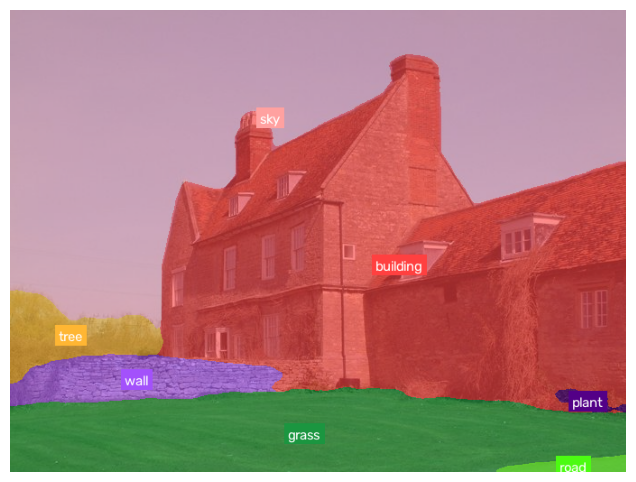

In [6]:
sv.plot_image(annotate(image, segformer_detections), size=(10, 6))

Each detection is an ordinary `sv.Detections` row, so the usual tools apply. For example, the share of the image taken by each class is the area of its mask:

In [7]:
coverage = segformer_detections.area / (height * width)
for name, share in sorted(
    zip(segformer_detections["class_name"], coverage), key=lambda item: -item[1]
)[:5]:
    print(f"{str(name):<12} {share:6.1%}")

building      39.0%
sky           38.7%
grass         15.3%
wall           3.5%
tree           2.6%


## Mask2Former

Mask2Former predicts a fixed set of masks, each with a class score, and the semantic map is the combination of them. The checkpoint below is the semantic-segmentation variant, so its post-processing returns the same `(H, W)` map as SegFormer.

In [8]:
mask2former_name = "facebook/mask2former-swin-tiny-ade-semantic"
mask2former_processor = AutoImageProcessor.from_pretrained(mask2former_name)
mask2former = AutoModelForUniversalSegmentation.from_pretrained(mask2former_name).to(
    device
)

with torch.no_grad():
    inputs = mask2former_processor(images=pil_image, return_tensors="pt").to(device)
    outputs = mask2former(**inputs)

mask2former_map = mask2former_processor.post_process_semantic_segmentation(
    outputs, target_sizes=[(height, width)]
)[0]
mask2former_detections = to_detections(
    mask2former_map.cpu().numpy(), mask2former.config.id2label
)
print(f"{len(mask2former_detections)} classes found")

8 classes found


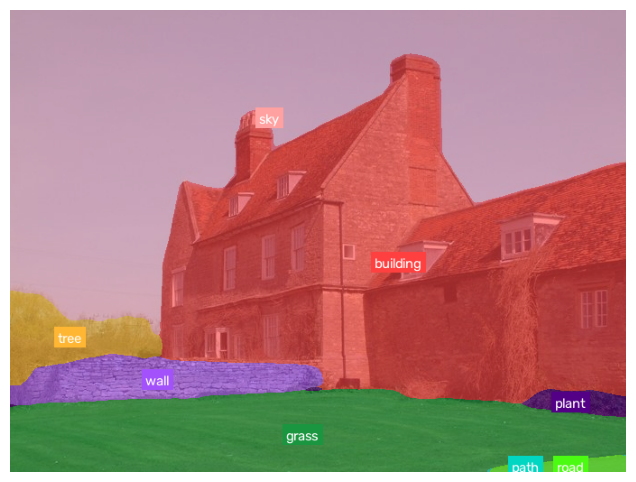

In [9]:
sv.plot_image(annotate(image, mask2former_detections), size=(10, 6))

## OneFormer

OneFormer is a single network for semantic, instance and panoptic segmentation. A text prompt, `task_inputs=["semantic"]`, chooses which output it produces. Only the processor call differs from the models above.

In [10]:
oneformer_name = "shi-labs/oneformer_ade20k_swin_tiny"
oneformer_processor = OneFormerProcessor.from_pretrained(oneformer_name)
oneformer = OneFormerForUniversalSegmentation.from_pretrained(oneformer_name).to(device)

with torch.no_grad():
    inputs = oneformer_processor(
        images=pil_image, task_inputs=["semantic"], return_tensors="pt"
    ).to(device)
    outputs = oneformer(**inputs)

oneformer_map = oneformer_processor.post_process_semantic_segmentation(
    outputs, target_sizes=[(height, width)]
)[0]
oneformer_detections = to_detections(
    oneformer_map.cpu().numpy(), oneformer.config.id2label
)
print(f"{len(oneformer_detections)} classes found")

8 classes found


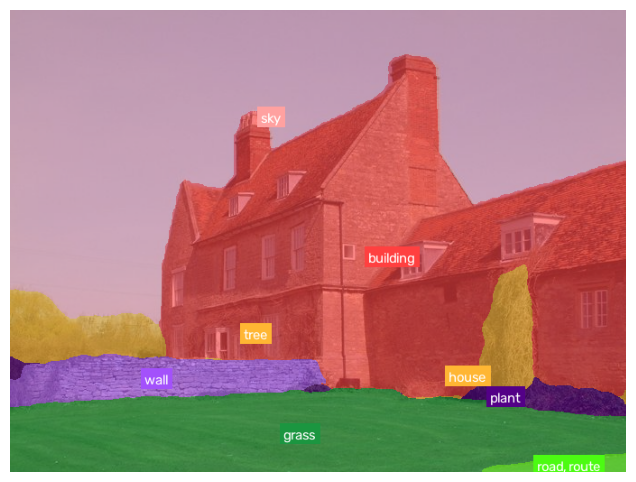

In [11]:
sv.plot_image(annotate(image, oneformer_detections), size=(10, 6))

## Compare the models

Because the three models share one label set and one output type, comparing them is a loop over `sv.Detections`.

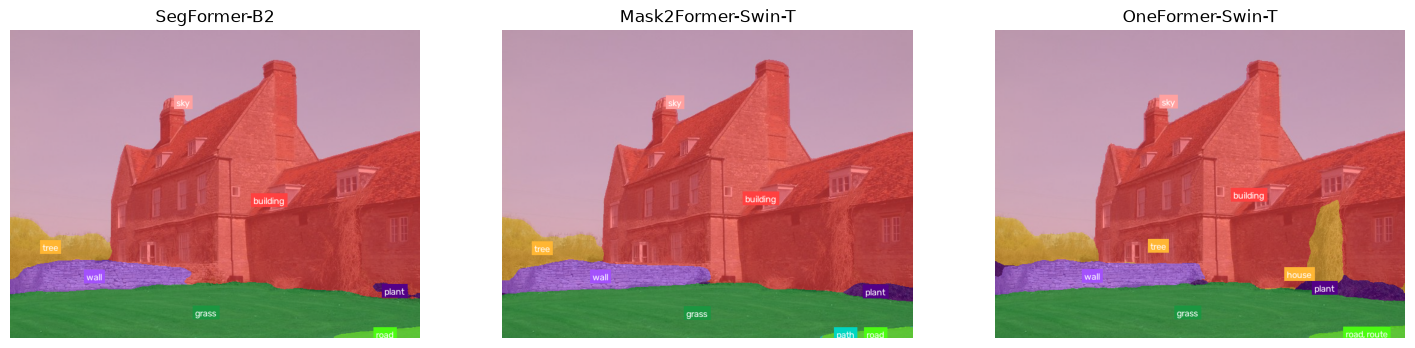

In [12]:
results = {
    "SegFormer-B2": segformer_detections,
    "Mask2Former-Swin-T": mask2former_detections,
    "OneFormer-Swin-T": oneformer_detections,
}

sv.plot_images_grid(
    images=[annotate(image, detections) for detections in results.values()],
    grid_size=(1, 3),
    titles=list(results),
    size=(18, 5),
)

Classes that every model found, and classes only one of them reported, show where the models disagree:

In [13]:
class_sets = {name: set(map(str, d["class_name"])) for name, d in results.items()}
shared = set.intersection(*class_sets.values())
print(f"All three agree on {len(shared)} classes: {sorted(shared)}")
for name, classes in class_sets.items():
    others = set.union(*(c for n, c in class_sets.items() if n != name))
    print(f"Only {name}: {sorted(classes - others)}")

All three agree on 6 classes: ['building', 'grass', 'plant', 'sky', 'tree', 'wall']
Only SegFormer-B2: []
Only Mask2Former-Swin-T: ['path']
Only OneFormer-Swin-T: ['house', 'road, route']


How closely two models agree pixel by pixel is the share of pixels that carry the same class id:

In [14]:
maps = {
    "SegFormer-B2": segformer_map,
    "Mask2Former-Swin-T": mask2former_map.cpu().numpy(),
    "OneFormer-Swin-T": oneformer_map.cpu().numpy(),
}
names = list(maps)
for i, first in enumerate(names):
    for second in names[i + 1 :]:
        agreement = float((maps[first] == maps[second]).mean())
        print(f"{first} vs {second}: {agreement:.1%} of pixels agree")

SegFormer-B2 vs Mask2Former-Swin-T: 98.5% of pixels agree
SegFormer-B2 vs OneFormer-Swin-T: 95.7% of pixels agree
Mask2Former-Swin-T vs OneFormer-Swin-T: 96.3% of pixels agree


## Large images: compact masks

A dense mask is one `(H, W)` boolean array per class, so a 4K image with 40 classes holds 40 full-size arrays. Pass `compact_masks=True` to store each mask as a bounding-box crop instead. The masks decode to the same pixels.

In [15]:
compact_detections = sv.Detections.from_semantic_segmentation(
    segformer_map,
    class_map={str(i): n for i, n in segformer.config.id2label.items()},
    background_id=None,
    compact_masks=True,
)

print(type(compact_detections.mask).__name__)
print(np.array_equal(np.asarray(compact_detections.mask), segformer_detections.mask))

CompactMask
True


## Roboflow Inference

Models trained and deployed on Roboflow return the label map as a base64-encoded PNG. Pass it to `from_semantic_segmentation` as it is: there is nothing to decode. These models use id `0` for background, so the default `background_id=0` is the right setting. If the response includes a `confidence_mask`, pass that too and each detection gets the mean confidence of its pixels.

```python
from inference import get_model

model = get_model("your-project/1", api_key="<ROBOFLOW_API_KEY>")
result = model.infer(image)[0]

detections = sv.Detections.from_semantic_segmentation(
    result.predictions.segmentation_mask,
    class_map=result.predictions.class_map,
    confidence_mask=result.predictions.confidence_mask,
)
```

`sv.Detections.from_inference` does not accept this response, because it holds one label map instead of a list of objects. It raises an error that points to `from_semantic_segmentation`.

## What next

- Filter classes with the usual `sv.Detections` indexing, for example `detections[detections["class_name"] == "person"]`.
- Use `sv.Detections.from_semantic_segmentation` with `sv.PolygonAnnotator` or `sv.HaloAnnotator` for other looks.
- Semantic segmentation cannot count people, because it does not separate them. For that, use an instance segmentation model with `from_inference`, `from_ultralytics` or `from_transformers`.